# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Naufal Fadhilah
- **Email:** ds322b6x1345@student.devacademy.id
- **ID Dicoding:** DS322B6X1345

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda pada setiap musim selama tahun 2011–2012, dan musim apa yang memiliki jumlah penyewaan tertinggi?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca selama tahun 2011–2012, dan kondisi cuaca apa yang memiliki jumlah penyewaan terendah?


## Import Semua Packages/Library yang Digunakan

In [33]:
# Memanggil library yang diperlukan untuk analisis
import os
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)


## Data Wrangling

### Gathering Data

#### Load df ...

In [34]:
day_df = pd.read_csv('day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [35]:
# Membaca dataset hour
hour_df = pd.read_csv('hour.csv')

# Menampilkan 5 baris pertama
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)

data day
- Dataset Bike Sharing berisi catatan jumlah penyewaan sepeda harian.
- Dataset memuat informasi waktu, kondisi cuaca, serta jumlah penyewaan oleh pengguna terdaftar dan pengguna kasual.

data hour
- Dataset hour_df memiliki informasi penyewaan sepeda berdasarkan jam.
- Dataset mencakup beberapa informasi, seperti tanggal, musim, bulan, jam penyewaan, kondisi cuaca, suhu, kelembapan, dan kecepatan angin.
- Terdapat kolom hr yang menunjukkan jam penyewaan sepeda, sehingga dataset dapat digunakan untuk menganalisis pola penyewaan berdasarkan waktu.
- Kolom casual menunjukkan jumlah pengguna kasual, sedangkan registered menunjukkan jumlah pengguna terdaftar.
- Kolom cnt menunjukkan total jumlah penyewaan sepeda setiap jam.

### Assessing Data

#### Identifying ... problem

In [36]:
# Inconsistent Value (data day)
day_df.dtypes

,0
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64
temp,float64


In [37]:
# Mengidentifikasi outlier (data day)
kolom_numerik = ['hum', 'windspeed', 'casual']

for kolom in kolom_numerik:
    Q1 = day_df[kolom].quantile(0.25)
    Q3 = day_df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (day_df[kolom] < batas_bawah) |
        (day_df[kolom] > batas_atas)
    ).sum()

    print(f'{kolom}: {jumlah_outlier} outlier')

hum: 2 outlier
windspeed: 13 outlier
casual: 44 outlier


In [38]:
# Memeriksa jumlah missing value (data hour)
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [39]:
# Memeriksa jumlah data duplikat (data hour)
hour_df.duplicated().sum()

np.int64(0)

**Steps to Take:**

data day
- Mengubah tipe data kolom dteday dari object menjadi datetime agar sesuai dengan informasi tanggal yang disimpan.
- Mengidentifikasi outlier menggunakan metode Interquartile Range (IQR) pada kolom hum, windspeed, dan casual.
- Memeriksa nilai yang terindikasi outlier sebelum menentukan tindakan penanganan.
- Tidak langsung menghapus outlier karena nilai tersebut mungkin masih merepresentasikan kondisi aktual dalam data.

data hour
- Memeriksa missing value pada seluruh kolom menggunakan isna().sum().
- Memeriksa data duplikat menggunakan duplicated().sum().
- Tidak melakukan penghapusan atau pengisian data karena tidak ditemukan masalah pada kedua pemeriksaan tersebut.

**Insight:** (Opsional)

data day
- Kolom dteday memiliki tipe data object, padahal berisi informasi tanggal sehingga perlu dikonversi menjadi datetime.
- Ditemukan indikasi outlier pada kolom hum sebanyak 2 data.
- Ditemukan indikasi outlier pada kolom windspeed sebanyak 13 data.
- Ditemukan indikasi outlier pada kolom casual sebanyak 44 data.
- Kolom temp, atemp, registered, dan cnt tidak menunjukkan adanya outlier berdasarkan metode IQR.
- Data yang terindikasi outlier tetap dipertahankan sementara karena perlu pemeriksaan lebih lanjut sebelum diputuskan untuk dihapus.

data hour
- Tidak ditemukan missing value pada seluruh kolom dataset hour_df.
- Tidak ditemukan data duplikat sehingga setiap baris data tercatat secara unik.
- Dataset hour_df tidak memerlukan penanganan khusus terkait missing value dan data duplikat.


### Cleaning Data

#### Fixing ... problem

In [40]:
# Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# Memeriksa tipe data setelah perubahan
day_df['dteday'].dtype

dtype('<M8[ns]')

**Insight:** (Opsional)
- Tipe data kolom dteday berhasil diperbaiki menjadi datetime.
- Ditemukan 2 outlier pada kolom hum.
- Ditemukan 13 outlier pada kolom windspeed.
- Ditemukan 44 outlier pada kolom casual.
- Data outlier tetap dipertahankan agar informasi asli dataset tidak hilang.

## Exploratory Data Analysis (EDA)

### Explore ...

In [41]:
# Menampilkan statistik deskriptif dataset (data day)
day_df.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [42]:
# Melihat ringkasan statistik dataset (data hour)
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Insight:** (Opsional)

data day
- Dataset Bike Sharing memiliki 731 data pengamatan selama periode Januari 2011 hingga Desember 2012.
- Rata-rata jumlah penyewaan sepeda (cnt) adalah sekitar 4.504 pengguna per hari.
- Rata-rata pengguna terdaftar (registered) sebanyak 3.656 pengguna per hari.
- Rata-rata pengguna kasual (casual) sebanyak 848 pengguna per hari.
- Jumlah pengguna terdaftar memiliki rata-rata lebih tinggi dibandingkan pengguna kasual.

data hour
- Dataset hour_df memiliki 17.379 baris data yang mencakup periode 1 Januari 2011 hingga 31 Desember 2012.
- Rata-rata total penyewaan sepeda (cnt) adalah sekitar 189 sepeda per jam.
- Rata-rata penyewaan oleh pengguna terdaftar (registered) sekitar 154 sepeda per jam, lebih tinggi dibandingkan pengguna kasual (casual) yang sekitar 36 sepeda per jam.
- Jumlah penyewaan tertinggi dalam satu jam mencapai 977 sepeda, sedangkan jumlah terendah adalah 1 sepeda.
- Rata-rata kelembapan (hum) sebesar 0,627 atau sekitar 62,7%.
- Data mencakup seluruh jam operasional dalam sehari, yaitu pukul 00.00–23.00.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

In [43]:
# Menghitung rata-rata penyewaan sepeda berdasarkan musim (data day)
day_df.groupby('season')['cnt'].mean()

,cnt
season,
1,2604.132597
2,4992.331522
3,5644.303191
4,4728.162921


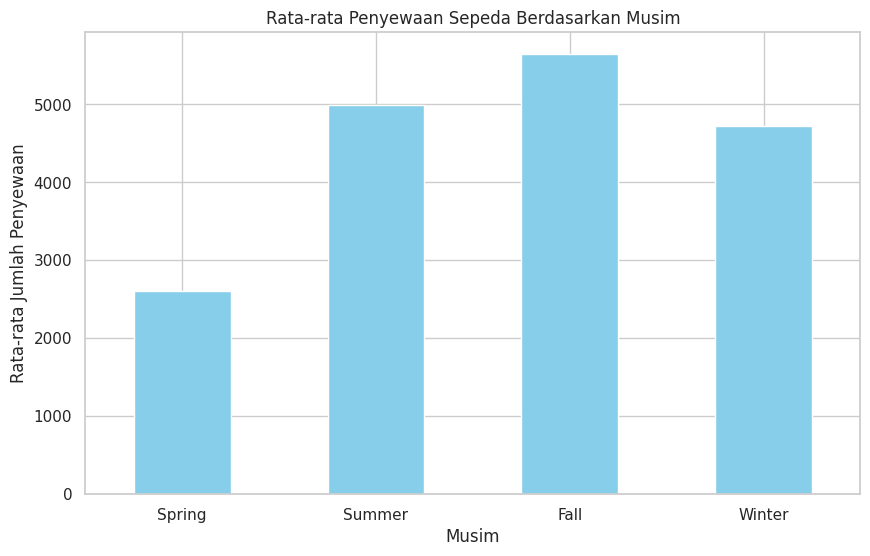

In [44]:
# Menghitung rata-rata penyewaan sepeda berdasarkan musim (data day)
rata_rata_musim = day_df.groupby('season')['cnt'].mean()

# Membuat diagram batang
rata_rata_musim.plot(kind='bar', color='skyblue')

# Mengatur judul dan label
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Musim')
plt.xlabel('Musim')
plt.ylabel('Rata-rata Jumlah Penyewaan')

# Mengganti angka musim menjadi nama musim
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['Spring', 'Summer', 'Fall', 'Winter'],
    rotation=0
)

plt.show()

### Pertanyaan 2:

In [45]:
# Menghitung rata-rata penyewaan sepeda berdasarkan kondisi cuaca (data day)
day_df.groupby('weathersit')['cnt'].mean()

,cnt
weathersit,
1,4876.786177
2,4035.862348
3,1803.285714


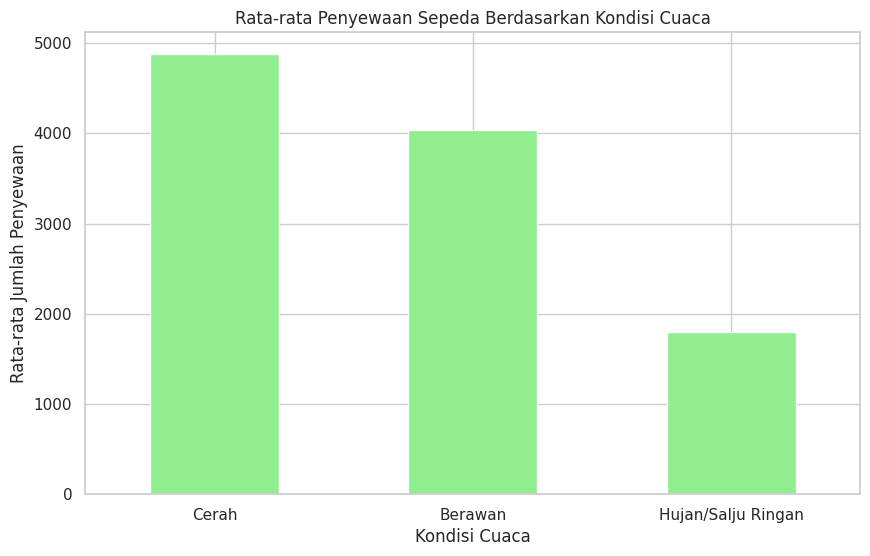

In [46]:
# Menghitung rata-rata penyewaan berdasarkan kondisi cuaca (data day)
rata_rata_cuaca = day_df.groupby('weathersit')['cnt'].mean()

# Membuat diagram batang
rata_rata_cuaca.plot(kind='bar', color='lightgreen')

# Mengatur judul dan label
plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')

# Mengatur label kondisi cuaca
plt.xticks(
    ticks=[0, 1, 2],
    labels=['Cerah', 'Berawan', 'Hujan/Salju Ringan'],
    rotation=0
)

plt.show()

In [47]:
# Menghitung rata-rata penyewaan sepeda berdasarkan jam (data hour)
rata_rata_jam = hour_df.groupby('hr')['cnt'].mean()

rata_rata_jam

,cnt
hr,
0,53.898072
1,33.375691
2,22.869930
3,11.727403
4,6.352941
5,19.889819
6,76.044138
7,212.064649
8,359.011004


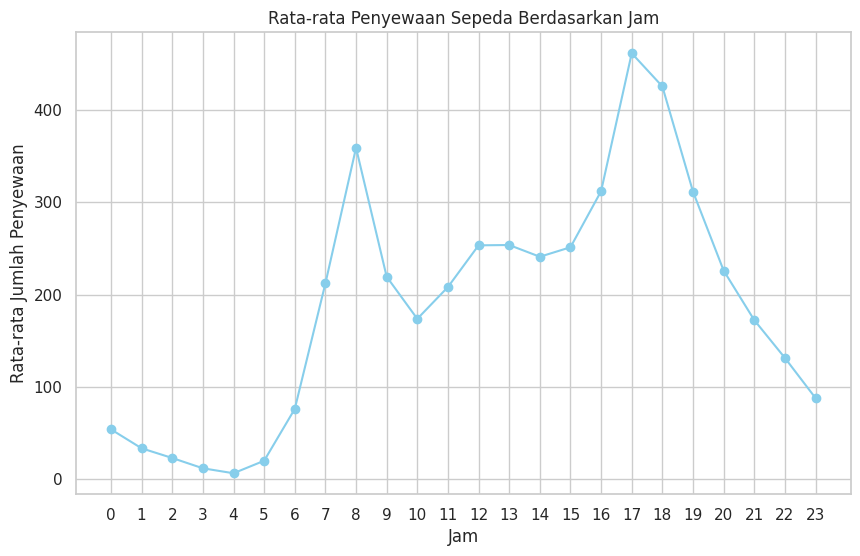

In [48]:
# Visualisasi rata-rata penyewaan berdasarkan jam (data hour)
rata_rata_jam.plot(kind='line', marker='o', color='skyblue')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Jam')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(24))
plt.grid(True)
plt.show()

In [49]:
# Menghitung rata-rata penyewaan berdasarkan kondisi cuaca (data hour)
rata_rata_cuaca_hour = hour_df.groupby('weathersit')['cnt'].mean()

rata_rata_cuaca_hour

,cnt
weathersit,
1,204.869272
2,175.165493
3,111.579281
4,74.333333


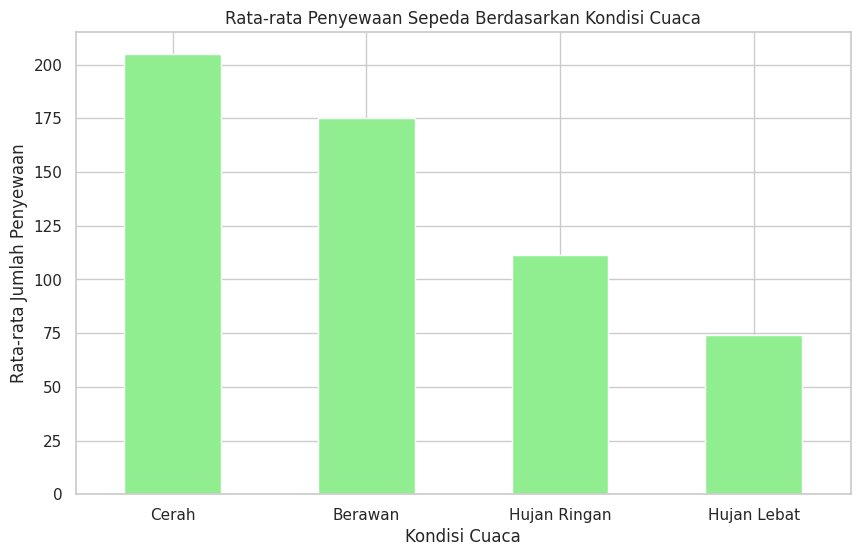

In [50]:
# Visualisasi rata-rata penyewaan berdasarkan kondisi cuaca (data hour)
rata_rata_cuaca_hour.plot(kind='bar', color='lightgreen')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['Cerah', 'Berawan', 'Hujan Ringan', 'Hujan Lebat'],
    rotation=0
)
plt.show()

**Insight:** (Opsional)

data day
- Rata-rata jumlah penyewaan sepeda selama periode tersebut adalah sekitar 4.504 penyewaan per hari.
- Jumlah pengguna terdaftar memiliki rata-rata lebih tinggi dibandingkan pengguna kasual.
- Berdasarkan musim, musim Fall memiliki rata-rata penyewaan sepeda tertinggi, yaitu sekitar 5.644 penyewaan, sedangkan musim Spring memiliki rata-rata terendah, yaitu sekitar 2.604 penyewaan.
- Berdasarkan kondisi cuaca, kondisi cuaca 1 memiliki rata-rata penyewaan tertinggi, yaitu sekitar 4.877 penyewaan, sedangkan kondisi cuaca 3 memiliki rata-rata terendah, yaitu sekitar 1.803 penyewaan.
- Jumlah penyewaan sepeda cenderung lebih rendah pada kondisi cuaca yang kurang baik.

data hour
- Rata-rata penyewaan tertinggi terjadi pada pukul 17.00, yaitu sekitar 461 sepeda per jam.
- Pukul 18.00 menjadi jam dengan penyewaan tertinggi kedua, sekitar 426 sepeda per jam.
- Penyewaan juga cukup tinggi pada pukul 08.00, yaitu sekitar 359 sepeda per jam.
- Rata-rata penyewaan terendah terjadi pada pukul 04.00, hanya sekitar 6 sepeda per jam.
- Pola ini menunjukkan bahwa penyewaan cenderung meningkat pada pagi hari dan mencapai puncak pada sore hari, kemungkinan berkaitan dengan aktivitas berangkat dan pulang kerja.
- Rata-rata penyewaan tertinggi terjadi pada kondisi cuaca 1 (Cerah, sedikit awan), yaitu sekitar 205 sepeda per jam.
- Kondisi cuaca 2 (Berkabut atau berawan) memiliki rata-rata sekitar 175 sepeda per jam.
- Kondisi cuaca 3 (Hujan ringan atau salju ringan) memiliki rata-rata sekitar 112 sepeda per jam.
- Rata-rata penyewaan terendah terjadi pada kondisi cuaca 4 (Hujan lebat atau salju lebat), yaitu sekitar 74 sepeda per jam.
- Semakin buruk kondisi cuaca, rata-rata jumlah penyewaan sepeda cenderung semakin menurun.

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**

(day) Berdasarkan hasil analisis musim, rata-rata penyewaan sepeda tertinggi terjadi pada musim Fall (gugur), yaitu sekitar 5.644 penyewaan per hari. Sementara itu, rata-rata penyewaan terendah terjadi pada musim Spring (semi), yaitu sekitar 2.604 penyewaan per hari.

(hour) Rata-rata penyewaan sepeda tertinggi terjadi pada pukul 17.00 dengan sekitar 461 penyewaan per jam, diikuti pukul 18.00 sebanyak 426 penyewaan per jam. Sementara itu, penyewaan terendah terjadi pada pukul 04.00, yaitu sekitar 6 penyewaan per jam. Hal ini menunjukkan bahwa permintaan penyewaan sepeda cenderung meningkat pada pagi dan sore hari, terutama pada jam berangkat dan pulang kerja.

- **Conclusion pertanyaan 2:**

(day) Berdasarkan kondisi cuaca, rata-rata penyewaan sepeda tertinggi terjadi pada kondisi cuaca cerah (weathersit 1), yaitu sekitar 4.877 penyewaan per hari. Sedangkan rata-rata penyewaan terendah terjadi pada kondisi cuaca hujan atau salju ringan (weathersit 3), yaitu sekitar 1.803 penyewaan per hari.

(hour) Rata-rata penyewaan tertinggi terjadi pada kondisi cuaca 1 (cerah atau sedikit berawan), yaitu sekitar 205 penyewaan per jam. Sebaliknya, rata-rata penyewaan terendah terjadi pada kondisi cuaca 4 (hujan lebat atau salju lebat), yaitu sekitar 74 penyewaan per jam. Hal ini menunjukkan bahwa kondisi cuaca yang semakin buruk cenderung diikuti penurunan jumlah penyewaan sepeda.


**Rekomendasi Action Item:**

day
- Perusahaan penyewaan sepeda dapat meningkatkan ketersediaan sepeda dan mempersiapkan operasional lebih optimal pada musim Fall karena memiliki rata-rata penyewaan tertinggi.
- Perusahaan dapat mempertimbangkan strategi promosi khusus pada musim Spring untuk meningkatkan jumlah penyewaan sepeda.
- Perusahaan dapat memanfaatkan kondisi cuaca cerah untuk menjalankan promosi penyewaan sepeda karena kondisi tersebut memiliki rata-rata penyewaan tertinggi.
- Pada kondisi cuaca kurang baik, perusahaan dapat mempertimbangkan strategi promosi yang sesuai untuk menarik minat pengguna.

hour
- Pengelolaan ketersediaan sepeda: Menambah stok sepeda pada jam sibuk, terutama pukul 07.00–09.00 dan 16.00–18.00.
- Strategi promosi: Memberikan promo pada jam-jam dengan permintaan rendah untuk meningkatkan jumlah penyewaan.
- Penyesuaian berdasarkan cuaca: Memanfaatkan kondisi cuaca cerah untuk menjalankan promosi dan memberikan informasi keselamatan kepada pengguna saat cuaca buruk.

In [51]:
import os

print(os.listdir())

['.config', 'hour.csv', 'streamlit.log', 'dashboard.py', 'day.csv', 'sample_data']


In [52]:
%%writefile dashboard.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Overwriting dashboard.py


In [53]:
%%writefile -a dashboard.py

# Konfigurasi halaman
st.set_page_config(
    page_title="Bike Sharing Dashboard",
    layout="wide"
)

# Membaca dataset
day_df = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

# Judul dashboard
st.title("Bike Sharing Dashboard")
st.markdown("Dashboard analisis penyewaan sepeda tahun 2011–2012")

Appending to dashboard.py


In [54]:
%%writefile -a dashboard.py

# Ringkasan Statistik
st.subheader("Ringkasan Statistik")

col1, col2, col3 = st.columns(3)

with col1:
    st.metric("Total Data Harian", f"{len(day_df):,}")

with col2:
    st.metric("Total Data Per Jam", f"{len(hour_df):,}")

with col3:
    st.metric(
        "Rata-rata Penyewaan Harian",
        f"{day_df['cnt'].mean():,.0f}"
    )

Appending to dashboard.py


In [55]:
%%writefile -a dashboard.py

# Rata-rata penyewaan berdasarkan musim
st.subheader("Rata-rata Penyewaan Sepeda Berdasarkan Musim")

season_avg = day_df.groupby('season')['cnt'].mean()

season_avg.index = ['Spring', 'Summer', 'Fall', 'Winter']

fig, ax = plt.subplots()
season_avg.plot(kind='bar', ax=ax, color='skyblue')

ax.set_xlabel("Musim")
ax.set_ylabel("Rata-rata Penyewaan")
ax.set_title("Penyewaan Sepeda Berdasarkan Musim")
ax.tick_params(axis='x', rotation=0)

st.pyplot(fig)

Appending to dashboard.py


In [56]:
%%writefile -a dashboard.py

# Rata-rata penyewaan berdasarkan kondisi cuaca
st.subheader("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca")

weather_avg = day_df.groupby('weathersit')['cnt'].mean()

weather_avg.index = [
    'Cerah',
    'Berawan',
    'Hujan Ringan'
]

fig, ax = plt.subplots()
weather_avg.plot(kind='bar', ax=ax, color='lightgreen')

ax.set_xlabel("Kondisi Cuaca")
ax.set_ylabel("Rata-rata Penyewaan")
ax.set_title("Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
ax.tick_params(axis='x', rotation=0)

st.pyplot(fig)

Appending to dashboard.py


In [57]:
%%writefile -a dashboard.py

# Rata-rata penyewaan berdasarkan jam
st.subheader("Rata-rata Penyewaan Sepeda Berdasarkan Jam")

hour_avg = hour_df.groupby('hr')['cnt'].mean()

fig, ax = plt.subplots()
hour_avg.plot(kind='line', marker='o', ax=ax, color='orange')

ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata Penyewaan")
ax.set_title("Penyewaan Sepeda Berdasarkan Jam")
ax.set_xticks(range(24))
ax.grid(True)

st.pyplot(fig)

Appending to dashboard.py


In [58]:
%%writefile -a dashboard.py

# Rata-rata penyewaan berdasarkan kondisi cuaca per jam
st.subheader("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca (Per Jam)")

weather_hour_avg = hour_df.groupby('weathersit')['cnt'].mean()

weather_hour_avg.index = [
    'Cerah',
    'Berawan',
    'Hujan Ringan',
    'Hujan Lebat'
]

fig, ax = plt.subplots()
weather_hour_avg.plot(kind='bar', ax=ax, color='lightcoral')

ax.set_xlabel("Kondisi Cuaca")
ax.set_ylabel("Rata-rata Penyewaan")
ax.set_title("Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
ax.tick_params(axis='x', rotation=0)

st.pyplot(fig)

Appending to dashboard.py


In [59]:
!pip install streamlit

In [64]:
!streamlit run dashboard.py &>/content/streamlit.log &

In [70]:
!streamlit run dashboard.py --server.port 8501 --server.address 0.0.0.0 --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit.log 2>&1 &

In [71]:
!cat /content/streamlit.log



2026-11-15 08:45:24.586 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.70.220.152:8501



In [72]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-use4a0-3qo1li15qacbk-a.us-east4.prod.r.colab.dev
